# 4 · What do the experimental controls tell us?

**Question:** Does a result survive different validation patients and a fairer training budget?

For readers familiar with training and validation. We examine patient-group
validation, data volume, matched optimizer steps and crossed subset draws.
All cells read the committed summaries; no training or dataset download is required.

**Route:** validation support → grouped outcomes → exposure confounding → paired controls.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'fedecg/models.py').is_file())
sys.path.insert(0, str(ROOT))
from notebooks._support import CLASSES, COLORS, NAMES, read_table, read_json, setup, finish
setup()
%matplotlib inline

## Rotate the validation patients

Three held-out groups each contain seven of the 21 strict-DS1 patients. Each
model trains on the other 14 patients. Fixed-round predictions are pooled
across the 21 held-out patients separately for each seed. DS2 is not evaluated
in this stage. The nine fold/seed cells have overlapping training populations.

,Mean,Seed_SD,F_recall,Q_recall
Recipe,,,,
MLP + RR / balanced,0.3116,0.0032,0.0,0.0
MLP + RR / ce,0.2968,0.0083,0.0,0.0
MLP / ce,0.2820,0.0024,0.0,0.0


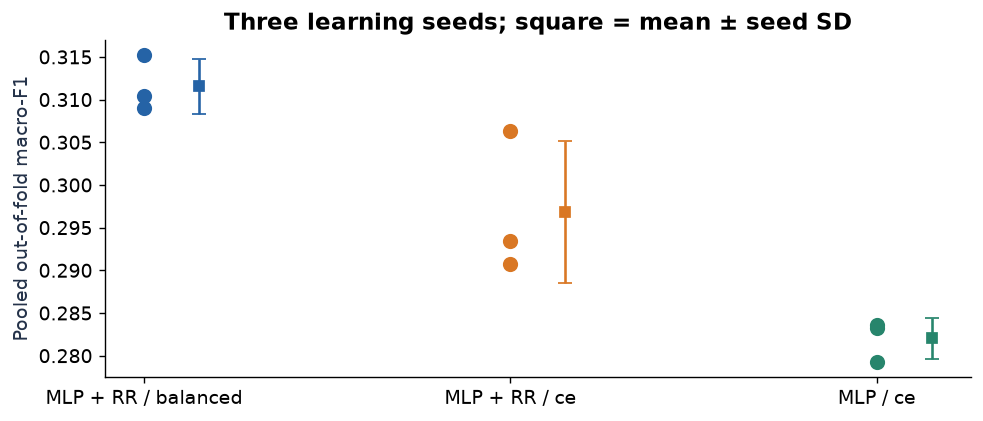

In [2]:
cv = read_table('grouped_cv_summary.csv')
cv['Recipe'] = cv.model.map(NAMES) + ' / ' + cv.loss
pooled_summary = cv.groupby('Recipe').agg(Mean=('oof_macro_f1', 'mean'),
                                        Seed_SD=('oof_macro_f1', 'std'),
                                        F_recall=('recall_F', 'mean'), Q_recall=('recall_Q', 'mean'))
display(pooled_summary)
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, (label, values) in enumerate(cv.groupby('Recipe')):
    ax.scatter(np.full(len(values), i), values.oof_macro_f1, s=60, color=COLORS[i])
    ax.errorbar(i + .15, values.oof_macro_f1.mean(), yerr=values.oof_macro_f1.std(),
                fmt='s', color=COLORS[i], capsize=4)
ax.set(xticks=range(3), xticklabels=pooled_summary.index, ylabel='Pooled out-of-fold macro-F1',
       title='Three learning seeds; square = mean ± seed SD')
finish(fig)

The balanced recipe ranks highest within this three-recipe internal shortlist.
F and Q recall remain zero. These scores and the main DS2 scores use different
training sets and evaluation populations, so their absolute difference is not
an estimate of a treatment effect.

In [3]:
fold_support = read_table('grouped_fold_class_support.csv')
held = fold_support.pivot(index='fold', columns='class', values='held_beats')[CLASSES]
display(held.rename(index=lambda k: f'Fold {k + 1}'))
rare = fold_support[fold_support['class'].isin(['F', 'Q'])]
display(rare[['fold', 'class', 'training_beats', 'held_beats', 'held_patients_with_class']])

class,N,S,V,F,Q
fold,,,,,
Fold 1,14474,194,1529,372,2
Fold 2,14481,186,1751,26,4
Fold 3,15258,436,310,14,2


,fold,class,training_beats,held_beats,held_patients_with_class
3,0,F,40,372,1
4,0,Q,6,2,1
8,1,F,386,26,3
9,1,Q,4,4,1
13,2,F,398,14,5
14,2,Q,6,2,1


## More data also means more updates under one local epoch

With fixed epochs, larger patient datasets produce more optimizer steps.
The chart shows this coupled change. The endpoint is the validation-selected
checkpoint; total steps describe the complete 30-round schedule.

,F1,SD,Steps,Seeds
n_train,,,,
6396,0.3194,0.0068,1800,5
20000,0.3471,0.0040,4890,5
40142,0.3545,0.0075,9630,5


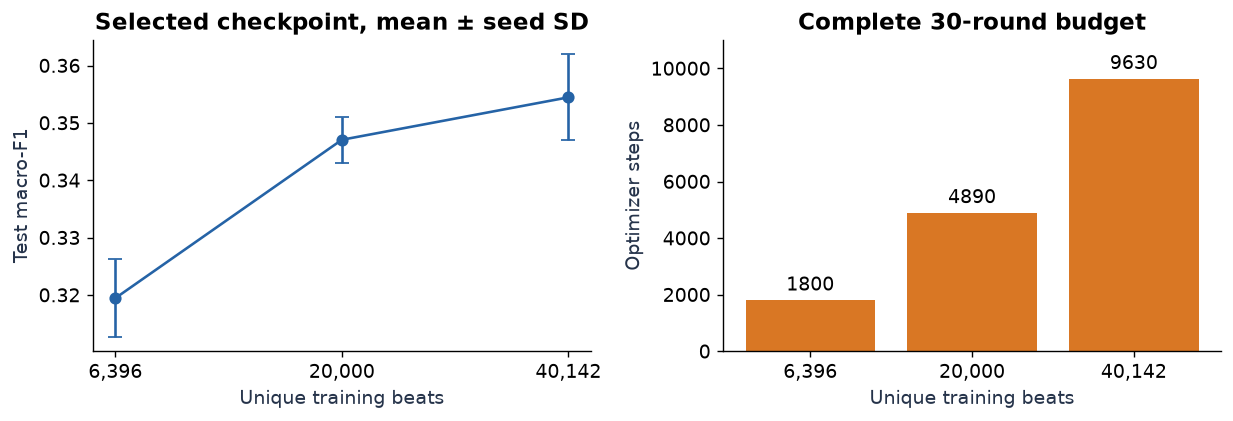

In [4]:
runs = read_table('run_summary.csv')
labels = ['volume_mlp_ce_6396', 'volume_mlp_ce_20000', 'main_mlp_ce']
volume = pd.concat([runs[runs.run.str.fullmatch(label + r'_s\d+')] for label in labels])
ledger = read_table('complete_run_ledger.csv').set_index('run')
volume = volume.assign(full_steps=volume.run.map(ledger.full_run_steps))
vol = volume.groupby('n_train').agg(F1=('best_macro_f1', 'mean'), SD=('best_macro_f1', 'std'),
                                  Steps=('full_steps', 'first'), Seeds=('seed', 'count'))
assert vol.Seeds.tolist() == [5, 5, 5]
display(vol)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
x = np.arange(len(vol))
axes[0].errorbar(x, vol.F1, yerr=vol.SD, fmt='o-', capsize=4)
axes[0].set(ylabel='Test macro-F1', title='Selected checkpoint, mean ± seed SD')
bars = axes[1].bar(x, vol.Steps, color=COLORS[1])
axes[1].bar_label(bars, fmt='%.0f', padding=3)
axes[1].set(ylabel='Optimizer steps', title='Complete 30-round budget', ylim=(0, 11000))
for ax in axes:
    ax.set_xticks(x, [f'{n:,}' for n in vol.index]); ax.set_xlabel('Unique training beats')
finish(fig)

## Match the optimizer steps and draws

Both arms now receive 9,630 optimizer steps and 1,232,640 replacement draws,
with full-reference aggregation weights. Their primary endpoint is **fixed
round 30**, avoiding a different selected-round budget. Draws are repeated
exposures, not additional unique patients or beats.

Sampling and weighting also differ from the one-epoch regime. This control
tests sensitivity to the training budget; the two regimes are not a causal
decomposition of data and optimization effects.

,Mean_F1,Seed_SD,Steps,Draws
train_size,,,,
6396,0.3461,0.0072,9630,1232640
40142,0.3511,0.0038,9630,1232640


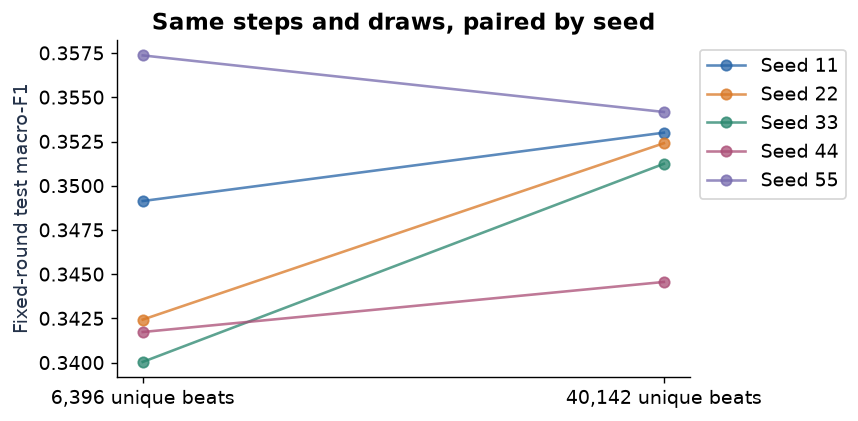

In [5]:
matched = read_table('equal_steps_summary.csv')
assert matched.local_steps.nunique() == 1 and matched.local_steps.iloc[0] == 9630
assert matched.sample_exposures.nunique() == 1 and matched.sample_exposures.iloc[0] == 1232640
display(matched.groupby('train_size').agg(Mean_F1=('test_final_macro_f1', 'mean'),
    Seed_SD=('test_final_macro_f1', 'std'), Steps=('local_steps', 'first'), Draws=('sample_exposures', 'first')))
wide = matched.pivot(index='seed', columns='train_size', values='test_final_macro_f1')
delta = wide[40142] - wide[6396]
uncertainty = read_json('equal_steps_uncertainty.json')
assert np.isclose(delta.mean(), uncertainty['difference_full_minus_small'])
fig, ax = plt.subplots(figsize=(7, 3.5))
for seed, row in wide.iterrows():
    ax.plot([0, 1], row.to_numpy(), 'o-', label=f'Seed {seed}', alpha=.75)
ax.set(xticks=[0, 1], xticklabels=['6,396 unique beats', '40,142 unique beats'],
       ylabel='Fixed-round test macro-F1', title='Same steps and draws, paired by seed')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); finish(fig)

## Change the subset draw as well as the learning seed

The sensitivity analysis crosses three subset draws with three learning seeds.
Full-data learners are reused across subset draws. The nine cells are a crossed
design, not nine independent learning seeds. Both controlled intervals below
span zero; the patient/subset/training interval accounts for all three sampled axes.

Learning seed,11,22,33
Subset seed,,,
20261028,0.0039,0.0100,0.0112
20261029,0.0060,0.0277,0.0059
20261030,0.0124,0.0149,0.0124


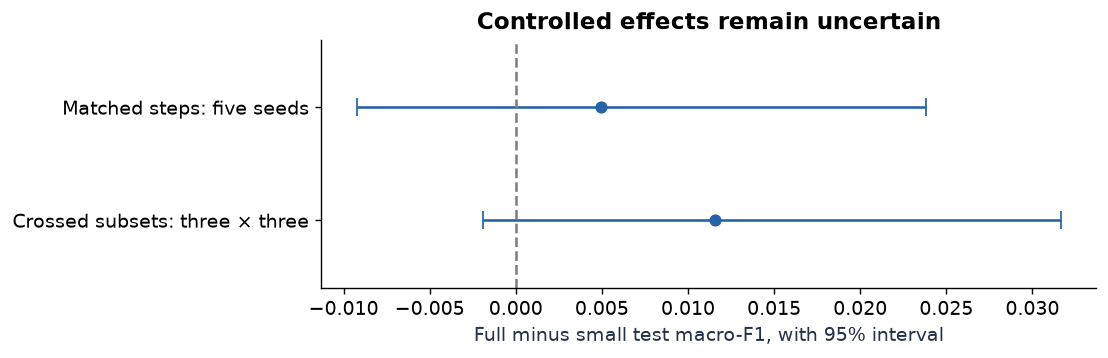

In [6]:
stability = read_table('subset_stability_summary.csv')
crossed = stability.pivot(index='subset_seed', columns='training_seed', values='difference')
display(crossed.rename_axis(index='Subset seed', columns='Learning seed'))
second = read_json('subset_stability_uncertainty.json')
points = [uncertainty['difference_full_minus_small'], second['mean_difference_full_minus_small']]
intervals = np.array([uncertainty['patient_seed_bootstrap_95ci'], second['subset_training_patient_bootstrap_95ci']])
fig, ax = plt.subplots(figsize=(9, 3))
ax.errorbar(points, [1, 0], xerr=np.array([points - intervals[:, 0], intervals[:, 1] - points]),
            fmt='o', color=COLORS[0], capsize=5)
ax.axvline(0, ls='--', color='gray')
ax.set(yticks=[1, 0], yticklabels=['Matched steps: five seeds', 'Crossed subsets: three × three'],
       ylim=(-.6, 1.6), xlabel='Full minus small test macro-F1, with 95% interval',
       title='Controlled effects remain uncertain')
finish(fig)

### Try it: how many distinct learning seeds are in the crossed analysis?

Count the rows, subset draws and learning seeds separately. The answer scaffold
below shows why a cell count should not be used as the replication count.

In [7]:
display(pd.DataFrame({'Quantity': ['Cells', 'Subset draws', 'Learning seeds'],
                      'Count': [len(stability), stability.subset_seed.nunique(), stability.training_seed.nunique()]}))
# Three full-data seed trajectories are reused; the nine deltas are dependent.

,Quantity,Count
0,Cells,9
1,Subset draws,3
2,Learning seeds,3


**Takeaway:** the controls expose validation sensitivity and weaken a claim that
unique training-beat availability alone explains the earlier apparent gain.
All of this remains exploratory after prior DS2 inspection.

**Optional extension:** inspect `training_subset_patient_allocation.csv`.
Class-stratified sampling retains all 17 clients but does not give them equal sizes.

**Next:** [5 · Model-transfer measurements](05_model_transfer_measurements.ipynb)